# Wildfire Evacuation Alert-Failure — Data Analysis

Loads the CSVs produced by `collect_data.py` (GDELT news coverage + Reddit
submissions/comments/subreddit-local for the Lahaina and Camp Fire case
studies) and runs burst detection on each, to compare when informal online
awareness spiked against the official warning timeline from each AG/
investigation report.

**In Colab:** run the cells top to bottom. The second code cell will prompt
you to upload CSVs — select all of them at once (multi-select works in the
picker): `lahaina_*.csv`, `camp_fire_*.csv`, including any
`*_reddit_local.csv` files you have.

**Running locally instead:** no upload needed — `DATA_DIR` defaults to
`../data`, the project's `data/` folder (this notebook lives in `src/`).

In [1]:
!pip install -q pandas matplotlib

In [2]:
import os

IN_COLAB = False
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    pass

DATA_DIR = "../data"  # project's data/ folder (notebook lives in src/)

if IN_COLAB:
    from google.colab import files
    print("Select all your CSVs (lahaina_*.csv, camp_fire_*.csv, *_reddit_local.csv) "
          "-- multi-select is fine.")
    uploaded = files.upload()
    DATA_DIR = "."

print(f"Looking for CSVs in: {os.path.abspath(DATA_DIR)}")

Looking for CSVs in: /Users/aneeshghosal/Documents/ML/data


## Discover which CSVs are present

In [3]:
import glob

CASES = ["lahaina", "camp_fire"]
SOURCE_SUFFIXES = {
    "gdelt": "_gdelt.csv",
    "reddit_submissions": "_reddit_submissions.csv",
    "reddit_comments": "_reddit_comments.csv",
}

def find_case_files(case, data_dir=DATA_DIR):
    found = {}
    for label, suffix in SOURCE_SUFFIXES.items():
        path = os.path.join(data_dir, f"{case}{suffix}")
        if os.path.exists(path):
            found[label] = path
    # Subreddit-local files are named <case>_<subreddit>_reddit_local.csv
    for path in sorted(glob.glob(os.path.join(data_dir, f"{case}_*_reddit_local.csv"))):
        sub = os.path.basename(path).replace(f"{case}_", "").replace("_reddit_local.csv", "")
        found[f"local_{sub}"] = path
    return found

case_files = {case: find_case_files(case) for case in CASES}
for case, found in case_files.items():
    print(f"{case}: found {list(found.keys())}")
    missing_core = set(SOURCE_SUFFIXES) - set(found)
    if missing_core:
        print(f"  (missing: {sorted(missing_core)} -- rerun collect_data.py for these if you need them)")

lahaina: found ['gdelt', 'reddit_submissions', 'reddit_comments', 'local_Maui']
camp_fire: found ['gdelt', 'reddit_submissions', 'reddit_comments', 'local_Chico']


## Load each CSV and parse timestamps

In [4]:
import pandas as pd

def load_with_timestamp(path, timestamp_col):
    df = pd.read_csv(path)
    if timestamp_col not in df.columns:
        print(f"  ! '{timestamp_col}' not in {os.path.basename(path)}; columns: {list(df.columns)}")
        df["_timestamp"] = pd.NaT
        return df
    col = df[timestamp_col]
    if col.dtype == object and col.astype(str).str.contains("T").any():
        # GDELT-style: 20230809T120000Z
        ts = pd.to_datetime(col, format="%Y%m%dT%H%M%SZ", errors="coerce")
    else:
        # Reddit/PullPush-style: unix epoch seconds
        ts = pd.to_datetime(col, unit="s", errors="coerce")
    df["_timestamp"] = ts
    return df

data = {}  # data[case][source_label] = DataFrame with a "_timestamp" column
for case, found in case_files.items():
    data[case] = {}
    for label, path in found.items():
        ts_col = "seendate" if label == "gdelt" else "created_utc"
        df = load_with_timestamp(path, ts_col)
        data[case][label] = df
        n_valid = df["_timestamp"].notna().sum()
        if n_valid:
            print(f"{case} / {label}: {len(df)} rows, "
                  f"{df['_timestamp'].min()} to {df['_timestamp'].max()}")
        else:
            print(f"{case} / {label}: {len(df)} rows, no valid timestamps")

lahaina / gdelt: 250 rows, 2023-08-11 19:30:00+00:00 to 2023-08-12 00:45:00+00:00
lahaina / reddit_submissions: 212 rows, 2023-08-09 08:02:56 to 2023-08-11 03:58:34
lahaina / reddit_comments: 445 rows, 2023-08-09 02:59:56 to 2023-08-11 03:39:00
lahaina / local_Maui: 262 rows, 2023-08-08 07:57:05 to 2023-08-11 03:50:32
camp_fire / gdelt: 250 rows, 2018-11-12 22:45:00+00:00 to 2018-11-13 00:45:00+00:00
camp_fire / reddit_submissions: 72 rows, 2018-11-08 21:18:08 to 2018-11-12 00:53:18
camp_fire / reddit_comments: 55 rows, 2018-11-08 23:03:31 to 2018-11-12 04:14:50


EmptyDataError: No columns to parse from file

## Burst detection

Same rolling z-score approach as `analyze_burst.py`: bin each source into
hourly buckets, compare each bucket to its own recent baseline, and flag
where activity spikes. Adjust `freq` / `baseline_window` / `z_threshold`
per source if a signal is too sparse or too noisy at the default settings.

In [5]:
def compute_burst(timestamps, freq="h", baseline_window=6, z_threshold=2.0):
    ts = timestamps.dropna()
    if ts.empty:
        return pd.DataFrame(columns=["count", "z_score", "burst"])
    counts = ts.dt.floor(freq).value_counts().sort_index()
    counts = counts.asfreq(freq, fill_value=0)
    rolling_mean = counts.rolling(baseline_window, min_periods=1).mean()
    rolling_std = counts.rolling(baseline_window, min_periods=1).std().fillna(0)
    z = (counts - rolling_mean) / rolling_std.replace(0, 1)
    result = pd.DataFrame({"count": counts, "z_score": z})
    result["burst"] = result["z_score"] >= z_threshold
    return result

burst_results = {}
for case in CASES:
    burst_results[case] = {}
    for label, df in data[case].items():
        result = compute_burst(df["_timestamp"])
        burst_results[case][label] = result
        if not result.empty and result["burst"].any():
            first_burst = result.index[result["burst"]].min()
            print(f"{case} / {label}: first burst at {first_burst}")
        else:
            print(f"{case} / {label}: no burst detected (check volume -- may be too sparse)")

lahaina / gdelt: no burst detected (check volume -- may be too sparse)
lahaina / reddit_submissions: no burst detected (check volume -- may be too sparse)
lahaina / reddit_comments: no burst detected (check volume -- may be too sparse)
camp_fire / gdelt: no burst detected (check volume -- may be too sparse)
camp_fire / reddit_submissions: first burst at 2018-11-11 17:00:00
camp_fire / reddit_comments: first burst at 2018-11-11 15:00:00


## Timeline plots

Fill in the official ignition / first-warning timestamps from your AG-report
timelines below (leave as `None` for anything not yet pinned down) -- they'll
show up as reference lines so you can see the burst points relative to them.

In [6]:
OFFICIAL_TIMESTAMPS = {
    "lahaina": {
        "ignition": "2023-08-08 15:00",   # placeholder -- confirm against AG report
        "first_warning": None,            # e.g. first evacuation order issued
    },
    "camp_fire": {
        "ignition": "2018-11-08 06:30",   # placeholder -- confirm
        "first_warning": None,
    },
}

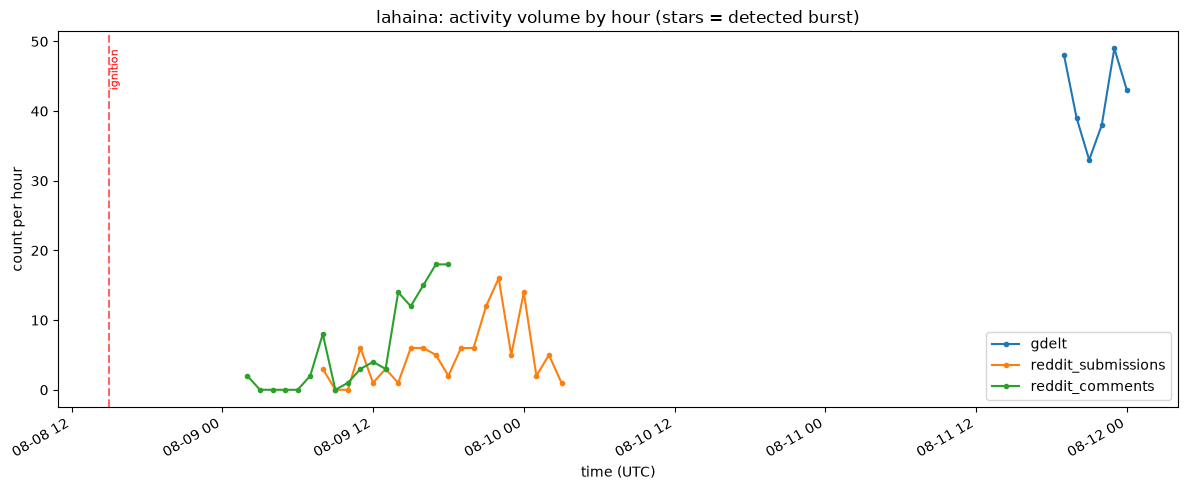

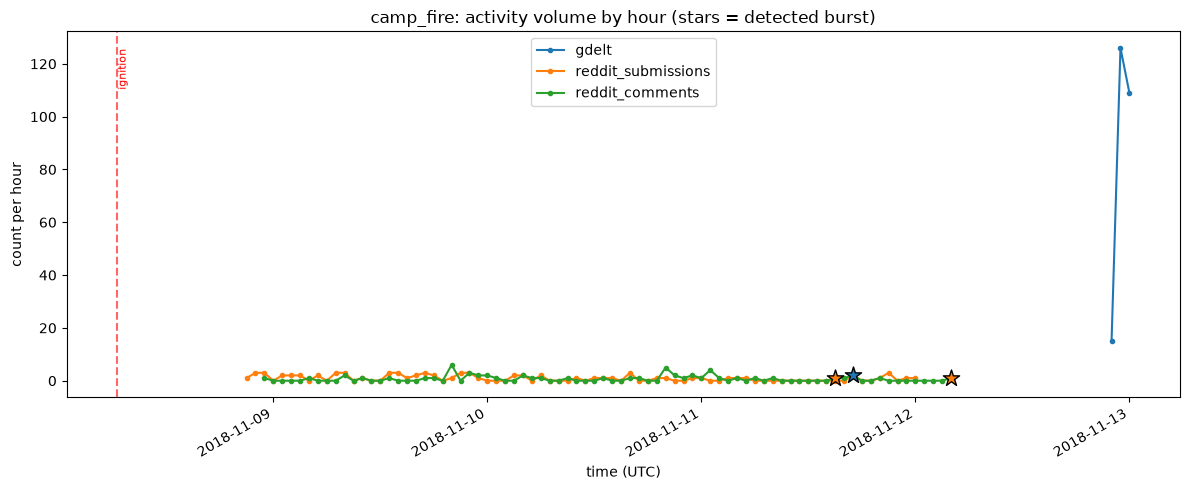

In [7]:
import matplotlib.pyplot as plt

def plot_case_timeline(case):
    fig, ax = plt.subplots(figsize=(12, 5))
    plotted_any = False
    for label, result in burst_results[case].items():
        if result.empty:
            continue
        plotted_any = True
        ax.plot(result.index, result["count"], marker="o", markersize=3, label=label)
        bursts = result[result["burst"]]
        if not bursts.empty:
            ax.scatter(bursts.index, bursts["count"], marker="*", s=150, zorder=5,
                       edgecolors="black")

    for name, ts_str in OFFICIAL_TIMESTAMPS.get(case, {}).items():
        if ts_str:
            ts = pd.to_datetime(ts_str)
            ax.axvline(ts, linestyle="--", color="red", alpha=0.6)
            ax.text(ts, ax.get_ylim()[1] * 0.95, name, rotation=90, color="red",
                    fontsize=8, va="top")

    if not plotted_any:
        print(f"{case}: nothing to plot (no sources with valid timestamps)")
        plt.close(fig)
        return

    ax.set_title(f"{case}: activity volume by hour (stars = detected burst)")
    ax.set_xlabel("time (UTC)")
    ax.set_ylabel("count per hour")
    ax.legend()
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

for case in CASES:
    plot_case_timeline(case)

## Quick content check
Sample titles/text per source, so you can eyeball whether the keyword search actually pulled relevant content.

In [8]:
for case in CASES:
    print(f"\n=== {case} ===")
    for label, df in data[case].items():
        print(f"\n-- {label} ({len(df)} rows) --")
        if "title" in df.columns:
            print(df["title"].head(5).to_string(index=False))
        elif "body" in df.columns:
            print(df["body"].astype(str).str.slice(0, 120).head(5).to_string(index=False))
        if "domain" in df.columns:
            print("Top domains:")
            print(df["domain"].value_counts().head(10))
        if "subreddit" in df.columns:
            print("Subreddit breakdown:")
            print(df["subreddit"].value_counts().head(10))


=== lahaina ===

-- gdelt (250 rows) --
Death toll from Maui wildfires rises to 67 as s...
Maui wildfires live updates : Death toll climbs...
Death toll from Maui wildfires rises to 67 as s...
Death toll in Maui disaster hits 67 , deadliest...
Maui wildfires live updates : Lahaina resembles...
Top domains:
domain
news.yahoo.com             9
kitv.com                   4
greensburgdailynews.com    3
thesunchronicle.com        3
latimes.com                3
wcvb.com                   3
wfmj.com                   3
myozarksonline.com         2
twincities.com             2
channelnewsasia.com        2
Name: count, dtype: int64

-- reddit_submissions (100 rows) --
           Front Street in Lahaina on fire (video)
                              Lahaina town on fire
BREAKING: Extremely dangerous massive wildfire ...
Almost all sides of Maui, Hawaii is currently o...
Lahaina fire (and kudos to Walmart and American...
Top domains:
domain
i.redd.it              13
v.redd.it               9
self